In [ ]:
# Non-Linear GRANGER CAUSALITY
import sys 
import nonlincausality as nlc
import matplotlib.pyplot as plt
from nonlincausality.utils import prepare_data_for_prediction
import pandas as pd
import seaborn as sns
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from collections import OrderedDict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

In [ ]:
pkl_path = Path("data\processed_data\combined_latest_snapshot_20251215.pkl")

with open(pkl_path, "rb") as f:
    data = pickle.load(f)
item = data[0]

print(item["sic_image"])
print(item["env"])

# --- SORT DATASET TEMPORALLY ---
combined_dataset = sorted(data, key=lambda x: x["date"])

[[   0    0    0 ... 2540 2540 2540]
 [   0    0    0 ... 2540 2540 2540]
 [   0    0    0 ... 2540 2540 2540]
 ...
 [2540 2540 2540 ...    0    0    0]
 [2540 2540 2540 ...    0    0    0]
 [2540 2540 2540 ...    0    0    0]]
{'u10': array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32), 'v10': array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32), 't2m': array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, na

In [8]:
item0 = combined_dataset[0]

print("Date:", item0["date"])
print("Missing env list:", item0["missing_env"])

for var in item0["env"]:
    print(var, type(item0["env"][var]))
    print(var, item0["env"][var].shape)

Date: 2025-09-17 00:00:00+07:00
Missing env list: []
u10 <class 'numpy.ndarray'>
u10 (448, 304)
v10 <class 'numpy.ndarray'>
v10 (448, 304)
t2m <class 'numpy.ndarray'>
t2m (448, 304)
msl <class 'numpy.ndarray'>
msl (448, 304)
sst <class 'numpy.ndarray'>
sst (448, 304)
tp <class 'numpy.ndarray'>
tp (448, 304)
mwd <class 'numpy.ndarray'>
mwd (448, 304)
mwp <class 'numpy.ndarray'>
mwp (448, 304)
swh <class 'numpy.ndarray'>
swh (448, 304)


In [ ]:
def build_ts_for_var(combined_dataset, var):
    sic_ts = []
    env_ts = []
    dates = []

    for item in combined_dataset:
        field = item["env"].get(var)
        if field is None:
            continue

        sic_val = np.nanmean(item["sic_image"])
        env_val = np.nanmean(field)

        if np.isnan(sic_val) or np.isnan(env_val):
            print("Both sic_val and env_val are NaN")
            continue

        sic_ts.append(sic_val)
        env_ts.append(env_val)
        dates.append(item["date"])

    return np.array(sic_ts), np.array(env_ts), np.array(dates)


In [10]:
def standardize_pair(x, y):
    scaler_x = StandardScaler()
    scaler_y = StandardScaler()

    x_s = scaler_x.fit_transform(x.reshape(-1,1)).ravel()
    y_s = scaler_y.fit_transform(y.reshape(-1,1)).ravel()

    return x_s, y_s

In [ ]:
results = OrderedDict()
alpha = 0.05

MAX_LAG = [1, 2, 3, 4, 5]
SIGNIF = 0.05

env_vars = ["u10", "v10", "t2m", "msl", "sst", "tp", "mwd", "mwp", "swh"]

params = {
    "kernel": ["rbf"],
    "C": [0.1, 1, 10],
    "epsilon": [0.01, 0.1]
}

for var in env_vars:
    print(f"\nProcessing {var} → SIC")
    
    sic_ts, env_ts, dates = build_ts_for_var(combined_dataset, var)

    if len(sic_ts) < 50:
        print(f"[SKIP] {var}: too few samples ({len(sic_ts)})")
        continue
    
    sic_s, env_s = standardize_pair(sic_ts, env_ts)
    data = np.column_stack([sic_s, env_s]).astype(float)
    
    T = data.shape[0]
    train = data[:int(0.7*T)]
    val   = data[int(0.7*T):int(0.85*T)]
    test  = data[int(0.85*T):]

    print(f"\nRunning causality: {var} → SIC | samples={len(sic_ts)}")

    try:
        result = nlc.nonlincausality_sklearn(
            x=train,
            sklearn_model=SVR,
            maxlag=MAX_LAG,
            params=params,
            x_test=test,
            x_val=val,
            plot=False
        )

        lag_results = {}
        for lag, res in result.items():
            lag_results[lag] = {
                "p_value": res.p_value,
                "statistic": res.test_statistic
            }

        causal_lags = [lag for lag, r in result.items() if r.p_value < alpha]

        min_p = min(r.p_value for r in result.values())
        best_lag = min(result, key=lambda k: result[k].p_value)

        results[var] = {
            "n_samples": T,
            "lag_results": lag_results,
            "causal_lags": causal_lags,
            "min_p_value": min_p,
            "best_lag": best_lag
        }
        
        print(f"  Significant lags: {causal_lags}")

    except Exception as e:
        print(f"[ERROR] {var}: {e}")



Processing u10 → SIC

Running causality: u10 → SIC | samples=84
Statistics value = 78.0 p-value = 0.000244140625
Statistics value = 66.0 p-value = 0.00048828125
Statistics value = 55.0 p-value = 0.0009765625
Statistics value = 45.0 p-value = 0.001953125
Statistics value = 36.0 p-value = 0.00390625
  Significant lags: [1, 2, 3, 4, 5]

Processing v10 → SIC

Running causality: v10 → SIC | samples=79
Statistics value = 66.0 p-value = 0.00048828125
Statistics value = 55.0 p-value = 0.0009765625
Statistics value = 45.0 p-value = 0.001953125
Statistics value = 36.0 p-value = 0.00390625
Statistics value = 28.0 p-value = 0.0078125
  Significant lags: [1, 2, 3, 4, 5]

Processing t2m → SIC

Running causality: t2m → SIC | samples=79
Statistics value = 66.0 p-value = 0.00048828125
Statistics value = 55.0 p-value = 0.0009765625
Statistics value = 45.0 p-value = 0.001953125
Statistics value = 36.0 p-value = 0.00390625
Statistics value = 28.0 p-value = 0.0078125
  Significant lags: [1, 2, 3, 4, 5]

P

In [12]:
print("\n" + "="*60)
print("NONLINEAR CAUSALITY SUMMARY (ENV → SIC)")
print("="*60)

for var, r in results.items():
    status = "YES" if len(r["causal_lags"]) > 0 else "NO"
    print(
        f"{var:5s} | causal: {status} | "
        f"min p={r['min_p_value']:.4f} | "
        f"best lag={r['best_lag']} | "
        f"N={r['n_samples']}"
    )



NONLINEAR CAUSALITY SUMMARY (ENV → SIC)
u10   | causal: YES | min p=0.0002 | best lag=1 | N=84
v10   | causal: YES | min p=0.0005 | best lag=1 | N=79
t2m   | causal: YES | min p=0.0005 | best lag=1 | N=79
msl   | causal: YES | min p=0.0005 | best lag=1 | N=79
sst   | causal: YES | min p=0.0005 | best lag=1 | N=79
tp    | causal: YES | min p=0.0010 | best lag=1 | N=79
mwd   | causal: YES | min p=0.0010 | best lag=3 | N=81
mwp   | causal: NO | min p=0.1697 | best lag=1 | N=81
swh   | causal: NO | min p=0.2349 | best lag=1 | N=81


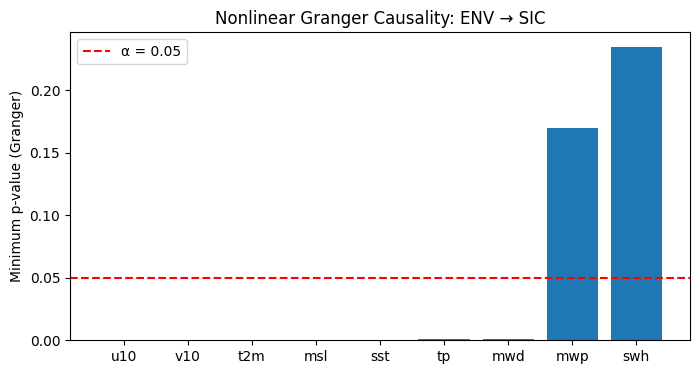

In [13]:
vars_ = list(results.keys())
pvals = [results[v]["min_p_value"] for v in vars_]

plt.figure(figsize=(8, 4))
plt.bar(vars_, pvals)
plt.axhline(0.05, color="red", linestyle="--", label="α = 0.05")
plt.ylabel("Minimum p-value (Granger)")
plt.title("Nonlinear Granger Causality: ENV → SIC")
plt.legend()
plt.show()
